# Explaining the curve stacker (xAI)

What the own approach (Branch A + p(AI) curves, `curve_stacker.ipynb`) relies on, on the fixed validation fold:

1. **Setup**: validation texts, their p(AI) curves at 64 / 128 / 256 tokens (cluster job 3016350), and the true boundaries of validation fusion texts that have a human twin.
2. **Highlighted texts**: each text coloured by the detector's p(AI), with the true boundary marked.
3. **Localisation**: how close the most AI-like stretch of a curve starts to the true boundary, and how well window p(AI) separates the parts before and after it.
4. **Detection vs edit strength**: how often fusion texts get any AI-like window, depending on how much of the rewritten part still matches the human original.
5. **What the stacker relies on**: permutation importance of feature groups and window sizes on validation macro-F1.

Everything here is computed on validation after all models were fixed; nothing is fitted on validation.

In [1]:
import html
import json
import os
import re
import sys
from pathlib import Path

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import AutoTokenizer

sys.path.insert(0, str(Path("../cluster").resolve()))
from encoder.curve_features import BASIC, CHANGEPOINT, CONTEXT, HIGH, SEGMENT, subsample
from encoder.data import LABELS, SEED, load_sets, prefix_key

COMPETITION = "ai-generated-text-detection-hw3-ucu-ai-2026"
FULL_JOB = "3016350"                                # job id of `make -C cluster full`
RESULTS_DIR = Path("../cluster/results") / FULL_JOB
FEATURE_DIR = Path("../outputs/curves")             # features and final probabilities from curve_stacker.ipynb
FIGURE_DIR = Path("../figures")
TOKENIZER = "xlm-roberta-base"                      # = FacebookAI/xlm-roberta-base
SIZES = [64, 128, 256]
N_PARTS = 4                                         # one part file per GPU
SIZE_COLORS = {64: "#2a78d6", 128: "#eb6834", 256: "#1baf7a"}

sets = load_sets(kagglehub.competition_download(COMPETITION))
val = sets["val"]
tokenizer = AutoTokenizer.from_pretrained(TOKENIZER)

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


## 1. Validation curves and twin boundaries
The curves are the detector's p(AI) for every window of every validation text, one window every size / 4 tokens. A validation fusion text with a human twin (same 200-character prefix, see `curves_check.ipynb` section 3) copies the twin word for word up to the **boundary**; the boundary is used here only to evaluate the curves.

In [2]:
def read_parts(pattern):
    """All per-GPU part files of one cluster output, concatenated."""
    parts = sorted(RESULTS_DIR.glob(pattern))
    assert len(parts) == N_PARTS, f"{pattern}: {len(parts)} part files"
    return pd.concat([pd.read_csv(path) for path in parts], ignore_index=True)


def boundary_char(fusion_text, human_text):
    """Character offset where the fusion text stops copying its human twin (end of the last copied word)."""
    copied = len(os.path.commonprefix([fusion_text.split(), human_text.split()]))
    word_ends = [m.end() for m in re.finditer(r"\S+", fusion_text)]
    return word_ends[copied - 1] if copied else 0


def bigram_overlap(fusion_text, human_text):
    """Share of the word bigrams of the fusion text's rewritten part that also occur in the twin's rest."""
    fusion_words, human_words = fusion_text.split(), human_text.split()
    copied = len(os.path.commonprefix([fusion_words, human_words]))
    fusion_rest, human_rest = fusion_words[copied:], human_words[copied:]
    fusion_bigrams = set(zip(fusion_rest, fusion_rest[1:]))
    human_bigrams = set(zip(human_rest, human_rest[1:]))
    return len(fusion_bigrams & human_bigrams) / max(len(fusion_bigrams), 1)


def twin_boundaries(df):
    """Boundary (character, token, share of the text) and rewrite overlap of fusion texts with one human twin in df."""
    humans = df[df["label"] == "human"]
    human_by_prefix = (humans.assign(prefix=prefix_key(humans["text"]))
                             .drop_duplicates("prefix", keep=False).set_index("prefix")["text"])
    fusion = df[df["label"] == "fusion"].assign(prefix=lambda d: prefix_key(d["text"]))
    fusion = fusion[fusion["prefix"].isin(human_by_prefix.index)]
    twins = human_by_prefix.loc[fusion["prefix"]].to_numpy()
    chars = [boundary_char(f, h) for f, h in zip(fusion["text"], twins)]
    enc = tokenizer(fusion["text"].tolist(), add_special_tokens=False, return_offsets_mapping=True, verbose=False)
    tokens = [int(np.searchsorted([start for start, _ in offsets], c)) for offsets, c in zip(enc["offset_mapping"], chars)]
    n_tokens = np.array([len(ids) for ids in enc["input_ids"]])
    return pd.DataFrame({"domain": fusion["domain"].to_numpy(), "boundary_char": chars, "boundary_tok": tokens,
                         "n_tokens": n_tokens, "boundary_share": np.array(tokens) / n_tokens,
                         "bigram_overlap": [bigram_overlap(f, h) for f, h in zip(fusion["text"], twins)]},
                        index=pd.Index(fusion["id"].to_numpy(), name="id"))


curves = {size: read_parts(f"curves_val_{size}.part*.csv.gz") for size in SIZES}
boundaries = twin_boundaries(val)
pd.DataFrame({"windows": {size: len(c) for size, c in curves.items()}}).T.assign(
    **{"val texts": len(val), "fusion texts with a twin boundary": len(boundaries)})

,64,128,256,val texts,fusion texts with a twin boundary
windows,1261585,598669,269735,27236,6051


## 2. Highlighted texts
Each word is coloured by the mean p(AI) of the 128-token windows that cover it (darker = more AI-like). **‖** marks the true boundary of a fusion text (where the copied human text ends). Long texts are cut to about 250 words around the boundary or the most AI-like region. The header shows the true label, Branch A's prediction and the final model's prediction (`curve_stacker.ipynb`, section 4). A standalone page with more examples is saved to `figures/curve_highlights.html`.

In [3]:
HIGHLIGHT_SIZE = 128
MAX_WORDS = 250
COLOR = "235, 104, 52"  # orange; background alpha = p(AI)


def final_predictions():
    """Validation labels of the final model: its saved probabilities with its class weights (human, fusion)."""
    configs = json.loads((FEATURE_DIR / f"best_configs_{FULL_JOB}.json").read_text())
    final = max(configs, key=lambda name: configs[name]["cv_macro_f1"])
    w_human, w_fusion = configs[final]["class_weights"]
    probs = pd.read_csv(FEATURE_DIR / f"final_probs_{FULL_JOB}_val.csv", index_col="id")[LABELS]
    return final, pd.Series(np.array(LABELS)[(probs.to_numpy() * [w_human, 1.0, w_fusion]).argmax(axis=1)], index=probs.index)


def char_scores(text, windows):
    """Mean p(AI) of the windows covering each character (NaN where no window covers it)."""
    total, count = np.zeros(len(text)), np.zeros(len(text))
    for start, end, p_ai in windows[["char_start", "char_end", "p_ai"]].itertuples(index=False):
        total[start:end] += p_ai
        count[start:end] += 1
    return np.divide(total, count, out=np.full(len(text), np.nan), where=count > 0)


def excerpt_words(text, scores, focus_char):
    """Word matches of an excerpt of at most MAX_WORDS words around focus_char (or the most AI-like word)."""
    words = list(re.finditer(r"\S+", text))
    if len(words) <= MAX_WORDS:
        return words
    if focus_char is None:
        focus_char = int(np.nanargmax(scores)) if not np.isnan(scores).all() else 0
    centre = next((i for i, m in enumerate(words) if m.end() >= focus_char), len(words) - 1)
    start = min(max(0, centre - MAX_WORDS // 2), len(words) - MAX_WORDS)
    return words[start:start + MAX_WORDS]


def highlight_html(text, scores, boundary=None):
    """The text (or an excerpt) as HTML, each word's background alpha = its mean p(AI); ‖ at the boundary."""
    words = excerpt_words(text, scores, boundary)
    parts = ["… "] if words[0].start() > 0 else []
    for match in words:
        if boundary is not None and match.start() >= boundary and "‖" not in "".join(parts):
            parts.append('<b style="color:#d1495b; font-size:1.3em">‖</b> ')
        alpha = np.nanmean(scores[match.start():match.end()]) if not np.isnan(scores[match.start():match.end()]).all() else 0
        parts.append(f'<span style="background: rgba({COLOR}, {alpha:.2f})">{html.escape(match.group())}</span> ')
    if words[-1].end() < len(text.rstrip()):
        parts.append("…")
    return "".join(parts)


def example_card(row, branch_a_pred, final_pred):
    """One highlighted example with its header (label, domain, length, predictions)."""
    windows = curves[HIGHLIGHT_SIZE][curves[HIGHLIGHT_SIZE]["id"] == row.id]
    boundary = boundaries.loc[row.id, "boundary_char"] if row.id in boundaries.index else None
    header = (f"<b>{row.label}</b> · {row.domain} · {len(row.text.split())} words · "
              f"Branch A: <b>{branch_a_pred[row.id]}</b> · final: <b>{final_pred[row.id]}</b>")
    body = highlight_html(row.text, char_scores(row.text, windows), boundary)
    return (f'<div style="margin: 0 0 18px 0; max-width: 900px; font-family: sans-serif; font-size: 13px; line-height: 1.6">'
            f'<div style="color:#52514e; margin-bottom: 4px">{header}</div><div>{body}</div></div>')

In [4]:
def pick_examples(val, branch_a_pred, final_pred, specs, seed=SEED):
    """One validation text per spec (label, Branch A / final prediction, domain), at least 150 words long."""
    info = val.assign(branch_a=val["id"].map(branch_a_pred), final=val["id"].map(final_pred),
                      words=val["text"].str.split().str.len(), twin=val["id"].isin(boundaries.index))
    picked = []
    for spec in specs:
        candidates = info[info["words"] >= 150]
        for column, value in spec.items():
            candidates = candidates[candidates[column] == value]
        candidates = candidates[~candidates["id"].isin([row.id for row in picked])]
        if len(candidates):
            picked.append(next(candidates.sample(1, random_state=seed).itertuples()))
    return picked


branch_a_probs = read_parts("branch_a_probs_val.part*.csv").set_index("id")[LABELS]
branch_a_pred = pd.Series(np.array(LABELS)[branch_a_probs.to_numpy().argmax(axis=1)], index=branch_a_probs.index)
FINAL_MODEL, final_pred = final_predictions()

NOTEBOOK_EXAMPLES = [
    {"label": "fusion", "final": "fusion", "twin": True},
    {"label": "human", "branch_a": "fusion", "final": "human"},
    {"label": "ai", "final": "ai"},
]
PAGE_EXAMPLES = [
    {"label": "fusion", "final": "fusion", "twin": True, "domain": "student_essays"},
    {"label": "fusion", "final": "fusion", "twin": True, "domain": "bundestag"},
    {"label": "fusion", "final": "human", "twin": True, "domain": "cnn_news"},
    {"label": "human", "branch_a": "fusion", "final": "human", "domain": "euro_court_cases"},
    {"label": "human", "branch_a": "fusion", "final": "human", "domain": "blog_authorship_corpus"},
    {"label": "human", "final": "human", "domain": "house_of_commons"},
    {"label": "ai", "final": "ai", "domain": "cnn_news"},
    {"label": "ai", "final": "ai", "domain": "arxiv_papers"},
]
notebook_cards = [example_card(row, branch_a_pred, final_pred)
                  for row in pick_examples(val, branch_a_pred, final_pred, NOTEBOOK_EXAMPLES)]
page_cards = [example_card(row, branch_a_pred, final_pred)
              for row in pick_examples(val, branch_a_pred, final_pred, PAGE_EXAMPLES)]
(FIGURE_DIR / "curve_highlights.html").write_text(
    '<!DOCTYPE html><html><head><meta charset="utf-8"><title>p(AI) highlights</title></head><body style="padding: 20px">'
    f'<h2 style="font-family: sans-serif">Detector p(AI) per word (128-token windows), validation texts</h2>'
    f'<p style="font-family: sans-serif; color:#52514e">Darker orange = higher p(AI). ‖ = true boundary of a fusion text '
    f'(end of the copied human text). Final model: {html.escape(FINAL_MODEL)}.</p>'
    + "".join(page_cards) + "</body></html>")
print(f"final model: {FINAL_MODEL}; {len(page_cards)} examples saved to {FIGURE_DIR / 'curve_highlights.html'}")

final model: E2: Branch A + curves; 8 examples saved to ../figures/curve_highlights.html


In [5]:
display(HTML("".join(notebook_cards)))

## 3. Localisation vs the true boundary
For validation fusion texts with a known boundary:
- **Start error**: where the most AI-like stretch of the curve starts (`seg_start`: the first token of its first window, `curve_features.best_segment`) vs the true boundary, as a share of the text and in tokens. Only texts whose curve has such a stretch (a window above 0.5) count. A window is long, and its start lies before any rewritten token it contains, so the *window centre* is also shown as an alternative estimate.
- **Window AUC**: how well a window's p(AI) separates windows after the boundary from windows before it (windows that contain the boundary are left out), per window size and domain.

In [6]:
def localisation_errors(features, boundaries):
    """Per window size: share of twins with an AI-like stretch, and median / IQR of its start error."""
    rows = []
    for size in SIZES:
        has_segment = features.loc[boundaries.index, f"{size}_fine__seg_share"] > 0
        twins = boundaries[has_segment]
        seg_start = features.loc[twins.index, f"{size}_fine__seg_start"]
        estimates = {"window start": seg_start, "window centre": seg_start + (size - 2) / 2 / twins["n_tokens"]}
        for estimate, share in estimates.items():
            error = (share - twins["boundary_share"]).abs()
            error_tokens = error * twins["n_tokens"]
            rows.append({"size": size, "estimate": estimate, "twins with a stretch %": 100 * has_segment.mean(),
                         "median error (share)": error.median(),
                         "IQR (share)": error.quantile(0.75) - error.quantile(0.25),
                         "median error (tokens)": error_tokens.median(),
                         "IQR (tokens)": error_tokens.quantile(0.75) - error_tokens.quantile(0.25)})
    return pd.DataFrame(rows).set_index(["size", "estimate"])


val_features = pd.read_csv(FEATURE_DIR / f"features_{FULL_JOB}_val.csv", index_col="id")
localisation = localisation_errors(val_features, boundaries)
localisation.round(3)

twins with a stretch %  median error (share)  IQR (share)  \
size estimate                                                                   
64   window start                   92.018                 0.064        0.112   
     window centre                  92.018                 0.024        0.074   
128  window start                   82.400                 0.104        0.129   
     window centre                  82.400                 0.029        0.057   
256  window start                   67.212                 0.167        0.168   
     window centre                  67.212                 0.046        0.075   

                    median error (tokens)  IQR (tokens)  
size estimate                                            
64   window start                    39.0          32.0  
     window centre                   15.0          35.0  
128  window start                    71.0          38.0  
     window centre                   20.0          30.0  
256  window start                   120.0          64.0  
     window centre                   33.0          41.0

In [7]:
def window_auc(curves, boundaries):
    """AUC of p(AI) for windows after vs before the boundary, per window size, overall and per domain."""
    rows = []
    for size, windows in curves.items():
        windows = windows.merge(boundaries[["boundary_tok", "domain"]], left_on="id", right_index=True)
        side = np.select([windows["tok_end"] <= windows["boundary_tok"], windows["tok_start"] >= windows["boundary_tok"]],
                         ["before", "after"], "straddle")
        windows = windows[side != "straddle"].assign(after=side[side != "straddle"] == "after")
        for domain, group in [("all", windows), *windows.groupby("domain")]:
            if group["after"].nunique() == 2:
                rows.append({"domain": domain, "size": size, "AUC": roc_auc_score(group["after"], group["p_ai"])})
    return pd.DataFrame(rows).pivot(index="domain", columns="size", values="AUC")


window_auc(curves, boundaries).round(3)

size,64,128,256
domain,,,
all,0.681,0.684,0.691
arxiv_papers,0.739,0.742,0.737
blog_authorship_corpus,0.606,0.608,0.624
bundestag,0.718,0.726,0.740
cnn_news,0.589,0.624,0.680
euro_court_cases,0.674,0.669,0.664
house_of_commons,0.699,0.702,0.698
student_essays,0.804,0.819,0.846


## 4. Detection vs edit strength
How strongly was a fusion text rewritten? **Bigram overlap** = the share of word bigrams in the fusion text's rewritten part (after the copied prefix) that also occur in the human twin's rest: near 0 = rewritten freely, near 1 = lightly edited. A text counts as **detected** at a window size if at least one of its non-overlapping windows (every 4th window) has p(AI) > 0.5. For reference, the last row gives the same rate for validation *human* texts (false alarms).

In [8]:
OVERLAP_BINS = [0, 0.1, 0.3, 0.5, 0.7, 1.0]
OVERLAP_LABELS = ["0–0.1", "0.1–0.3", "0.3–0.5", "0.5–0.7", "0.7–1"]
FALSE_ALARMS = "human texts (false alarms)"
NON_OVERLAP = 4


def detected(curves, ids):
    """Per window size: whether each text has a non-overlapping window with p(AI) > HIGH."""
    return pd.DataFrame({size: subsample(windows[windows["id"].isin(ids)], NON_OVERLAP)
                         .groupby("id")["p_ai"].max().reindex(ids) > HIGH for size, windows in curves.items()})


def detection_by_overlap(curves, boundaries, human_ids):
    """Detection rate (%) per bigram-overlap bin and window size, plus the false-alarm rate on human texts."""
    hits = detected(curves, boundaries.index)
    bins = pd.cut(boundaries["bigram_overlap"], OVERLAP_BINS, labels=OVERLAP_LABELS, include_lowest=True)
    table = hits.groupby(bins, observed=True).mean().mul(100).assign(texts=hits.groupby(bins, observed=True).size())
    table.index = table.index.astype(str).rename("bigram overlap")
    humans = detected(curves, human_ids)
    table.loc[FALSE_ALARMS] = [*humans.mean().mul(100), len(humans)]
    return table


detection = detection_by_overlap(curves, boundaries, pd.Index(val.loc[val["label"] == "human", "id"]))
detection.round(1)

,64,128,256,texts
bigram overlap,,,,
0–0.1,87.8,79.7,65.7,1958
0.1–0.3,97.6,92.6,86.1,459
0.3–0.5,97.6,93.7,85.0,826
0.5–0.7,96.4,90.6,75.3,1046
0.7–1,80.2,61.6,36.7,1762
human texts (false alarms),50.0,13.2,2.4,6673


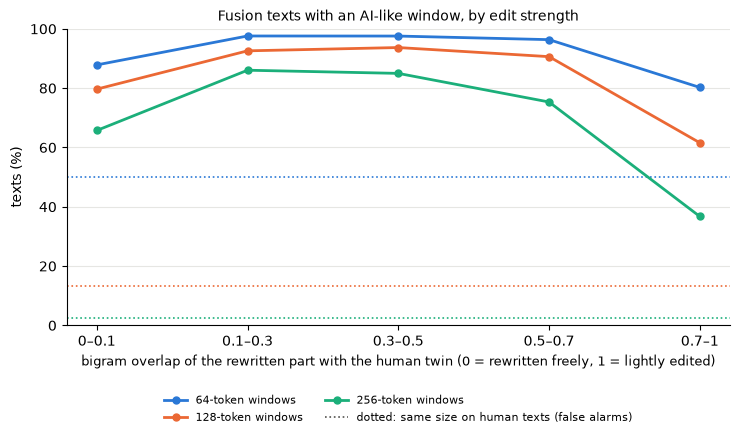

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.6))
fusion_rows = detection.drop(index=FALSE_ALARMS)
for size in SIZES:
    ax.plot(fusion_rows.index, fusion_rows[size], color=SIZE_COLORS[size], linewidth=2, marker="o", markersize=5,
            label=f"{size}-token windows")
    ax.axhline(detection.loc[FALSE_ALARMS, size], color=SIZE_COLORS[size], linewidth=1.2, linestyle=":")
ax.plot([], [], color="#52514e", linewidth=1.2, linestyle=":", label="dotted: same size on human texts (false alarms)")
ax.set(title="Fusion texts with an AI-like window, by edit strength",
       xlabel="bigram overlap of the rewritten part with the human twin (0 = rewritten freely, 1 = lightly edited)",
       ylabel="texts (%)", ylim=(0, 100))
ax.grid(axis="y", color="#e6e6e3", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.title.set_fontsize(10)
ax.xaxis.label.set_fontsize(9)
fig.tight_layout();

## 5. What the stacker relies on
The final model (the row with the highest CV macro-F1 in `curve_stacker.ipynb`, with its parameters and class weights from `outputs/curves/best_configs_<job>.json`) is refitted on the stacker set. **Permutation importance**: shuffle all columns of one group together across validation texts and measure how much validation macro-F1 drops (5 shuffles, seed 42). Groups are Branch A's probabilities, the curve feature groups (basic, changepoint, segment, context, cross-scale; all window sizes), and the window sizes (all curve features of one size).

In [10]:
BRANCH_A = [f"logp_{label}" for label in LABELS]
CURVE_GROUPS = {"basic": BASIC, "changepoint": CHANGEPOINT, "segment": SEGMENT, "context": CONTEXT}
MODELS = {"LogReg": LogisticRegression, "HGB": HistGradientBoostingClassifier}
N_REPEATS = 5


def stacker_table(set_name):
    """Branch A log-probabilities and cached curve features of one set, in the set's row order."""
    probs = read_parts(f"branch_a_probs_{set_name}.part*.csv").set_index("id")[LABELS]
    features = pd.read_csv(FEATURE_DIR / f"features_{FULL_JOB}_{set_name}.csv", index_col="id")
    return np.log(probs.clip(lower=1e-6)).add_prefix("logp_").join(features).loc[sets[set_name]["id"]]


def e2_columns(columns):
    """The E2 feature set: Branch A + every curve group at every size (fine stride) + cross-scale."""
    curve = [f"{size}_fine__{name}" for size in SIZES for names in CURVE_GROUPS.values() for name in names]
    return BRANCH_A + curve + [c for c in columns if c.startswith("cross_")]


def importance_groups(columns):
    """Column groups to permute together: Branch A, each curve group, cross-scale, each window size."""
    groups = {"Branch A": BRANCH_A}
    groups |= {f"group: {name}": [f"{size}_fine__{n}" for size in SIZES for n in names] for name, names in CURVE_GROUPS.items()}
    groups["group: cross-scale"] = [c for c in columns if c.startswith("cross_")]
    groups |= {f"size: {size}": [c for c in columns if c.startswith(f"{size}_fine__")] for size in SIZES}
    return groups


def weighted_labels(model, X, weights):
    """Labels of a fitted model with the class weights (human, fusion) applied to its probabilities."""
    classes = list(model.classes_)
    probs = model.predict_proba(X)[:, [classes.index(label) for label in LABELS]]
    return np.array(LABELS)[(probs * [weights[0], 1.0, weights[1]]).argmax(axis=1)]


def permutation_importance(model, X, y, weights, groups, seed=SEED):
    """Mean and std of the macro-F1 drop when the columns of each group are shuffled together."""
    base = f1_score(y, weighted_labels(model, X, weights), average="macro")
    rng = np.random.default_rng(seed)
    rows = []
    for name, columns in groups.items():
        drops = []
        for _ in range(N_REPEATS):
            shuffled = X.copy()
            shuffled[columns] = X[columns].to_numpy()[rng.permutation(len(X))]
            drops.append(base - f1_score(y, weighted_labels(model, shuffled, weights), average="macro"))
        rows.append({"group": name, "columns": len(columns), "macro-F1 drop": np.mean(drops), "std": np.std(drops)})
    return base, pd.DataFrame(rows).set_index("group").sort_values("macro-F1 drop", ascending=False)

In [11]:
configs = json.loads((FEATURE_DIR / f"best_configs_{FULL_JOB}.json").read_text())
final_config = configs[FINAL_MODEL]
assert final_config["feature_set"].startswith("E2"), f"final model is {final_config['feature_set']}, not E2"

X_stacker, X_val = stacker_table("stacker"), stacker_table("val")
columns = e2_columns(X_stacker.columns)
model = MODELS[final_config["model"]](**final_config["params"])
model = make_pipeline(StandardScaler(), model) if final_config["model"] == "LogReg" else model
model.fit(X_stacker[columns], sets["stacker"]["label"])
base_f1, importance = permutation_importance(model, X_val[columns], val["label"].to_numpy(),
                                             final_config["class_weights"], importance_groups(columns))
print(f"{FINAL_MODEL} ({final_config['model']}), refitted: validation macro-F1 {base_f1:.4f}")
importance.round(4)

E2: Branch A + curves (HGB), refitted: validation macro-F1 0.9344


,columns,macro-F1 drop,std
group,,,
Branch A,3,0.2488,0.0012
size: 256,20,0.0885,0.0010
group: basic,21,0.0832,0.0017
group: changepoint,18,0.0498,0.0013
size: 128,20,0.0238,0.0015
size: 64,20,0.0233,0.0010
group: segment,15,0.0034,0.0007
group: cross-scale,6,0.0024,0.0006
group: context,6,0.0004,0.0007


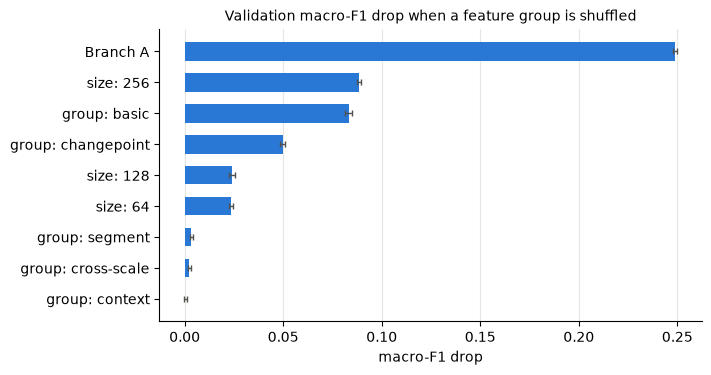

In [12]:
fig, ax = plt.subplots(figsize=(7, 3.8))
order = importance.sort_values("macro-F1 drop")
ax.barh(order.index, order["macro-F1 drop"], xerr=order["std"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": "#52514e", "elinewidth": 1, "capsize": 2})
ax.set(title="Validation macro-F1 drop when a feature group is shuffled", xlabel="macro-F1 drop")
ax.grid(axis="x", color="#e6e6e3", linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.title.set_fontsize(10);